In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

RESULTS_DIR = Path("../results")
FIGURES_DIR = Path("../figures")

df = pd.read_csv(
    RESULTS_DIR / "uber_with_clusters.csv"
)

df["Date/Time"] = pd.to_datetime(df["Date/Time"])
df["Date"] = df["Date/Time"].dt.date

print("FORECASTING DATA READY")
display(df.head())

FORECASTING DATA READY


,Date/Time,Lat,Lon,Base,Cluster,Date
0,2014-09-01 00:01:00,40.2201,-74.0021,B02512,6,2014-09-01
1,2014-09-01 00:01:00,40.7500,-74.0027,B02512,2,2014-09-01
2,2014-09-01 00:03:00,40.7559,-73.9864,B02512,0,2014-09-01
3,2014-09-01 00:06:00,40.7450,-73.9889,B02512,2,2014-09-01
4,2014-09-01 00:11:00,40.8145,-73.9444,B02512,0,2014-09-01


In [14]:
# Prepare daily pickup counts for forecasting

forecast_data = (
    df.groupby(["Date", "Cluster"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

forecast_data.index = pd.to_datetime(forecast_data.index)

# Use the first 23 days for training
# and the final 7 days for testing

train = forecast_data.iloc[:-7].copy()
test = forecast_data.iloc[-7:].copy()

print("FORECASTING DATASET")
print("Total days:", len(forecast_data))
print("Training days:", len(train))
print("Testing days:", len(test))
print("Clusters:", forecast_data.columns.tolist())

print("\nTRAINING PERIOD")
print(train.index.min().date(), "to", train.index.max().date())

print("\nTEST PERIOD")
print(test.index.min().date(), "to", test.index.max().date())

display(forecast_data.head())
forecast_data.to_csv(
    RESULTS_DIR / "04_daily_pickup_counts.csv"
)


FORECASTING DATASET
Total days: 30
Training days: 23
Testing days: 7
Clusters: [0, 1, 2, 3, 4, 5, 6]

TRAINING PERIOD
2014-09-01 to 2014-09-23

TEST PERIOD
2014-09-24 to 2014-09-30


Cluster,0,1,2,3,4,5,6
Date,,,,,,,
2014-09-01,5360,414,7336,1594,1843,445,2969
2014-09-02,10415,525,11466,1381,1834,429,2781
2014-09-03,11975,544,14255,963,1479,322,3093
2014-09-04,14277,567,17127,1035,1743,319,3292
2014-09-05,14940,647,19817,1053,1427,288,4147


In [15]:
# Seasonal Naïve Forecasting
# Predict each test day using the same weekday from the previous week

seasonal_predictions = train.iloc[-7:].copy()

# Assign the dates of the testing period
seasonal_predictions.index = test.index

print("SEASONAL NAÏVE FORECASTS")
display(seasonal_predictions)

print("\nACTUAL PICKUP COUNTS")
display(test)


SEASONAL NAÏVE FORECASTS


Cluster,0,1,2,3,4,5,6
Date,,,,,,,
2014-09-24,13801,461,15470,929,1326,347,3197
2014-09-25,14855,655,17919,1104,1712,391,3638
2014-09-26,14050,704,18867,1066,1752,365,4213
2014-09-27,11561,789,18483,770,1636,280,5345
2014-09-28,7363,552,13207,1404,1967,391,3736
2014-09-29,10689,556,11500,1094,1341,376,2756
2014-09-30,11326,612,13026,814,1110,295,3133



ACTUAL PICKUP COUNTS


Cluster,0,1,2,3,4,5,6
Date,,,,,,,
2014-09-24,11705,621,13104,884,1257,266,3464
2014-09-25,14265,623,16647,891,1512,371,3894
2014-09-26,12521,571,17163,915,1491,343,4500
2014-09-27,12240,771,18099,856,1373,258,5871
2014-09-28,8206,679,12225,1419,1750,442,4935
2014-09-29,11068,467,11501,1151,1518,379,3117
2014-09-30,13323,528,14111,851,1122,283,3213


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

evaluation_results = []

for cluster in test.columns:

    actual = test[cluster]
    predicted = seasonal_predictions[cluster]

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)

    evaluation_results.append({
        "Cluster": cluster,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("FORECASTING PERFORMANCE BY CLUSTER")
display(evaluation_df.round(2))
evaluation_df.to_csv(
    RESULTS_DIR / "04_seasonal_naive_evaluation.csv",
    index=False
)

print("\nOVERALL FORECASTING PERFORMANCE")
print("MAE:", round(mean_absolute_error(
    test.to_numpy().ravel(),
    seasonal_predictions.to_numpy().ravel()
), 2))

print("RMSE:", round(np.sqrt(mean_squared_error(
    test.to_numpy().ravel(),
    seasonal_predictions.to_numpy().ravel()
)), 2))


FORECASTING PERFORMANCE BY CLUSTER


,Cluster,MAE,MSE,RMSE
0,0,1159.00,1768928.14,1330.01
1,1,91.86,10820.43,104.02
2,2,1113.43,1772651.71,1331.41
3,3,86.29,11776.29,108.52
4,4,171.29,37230.43,192.95
5,5,30.14,1526.14,39.07
6,6,425.14,295741.71,543.82



OVERALL FORECASTING PERFORMANCE
MAE: 439.59
RMSE: 746.29


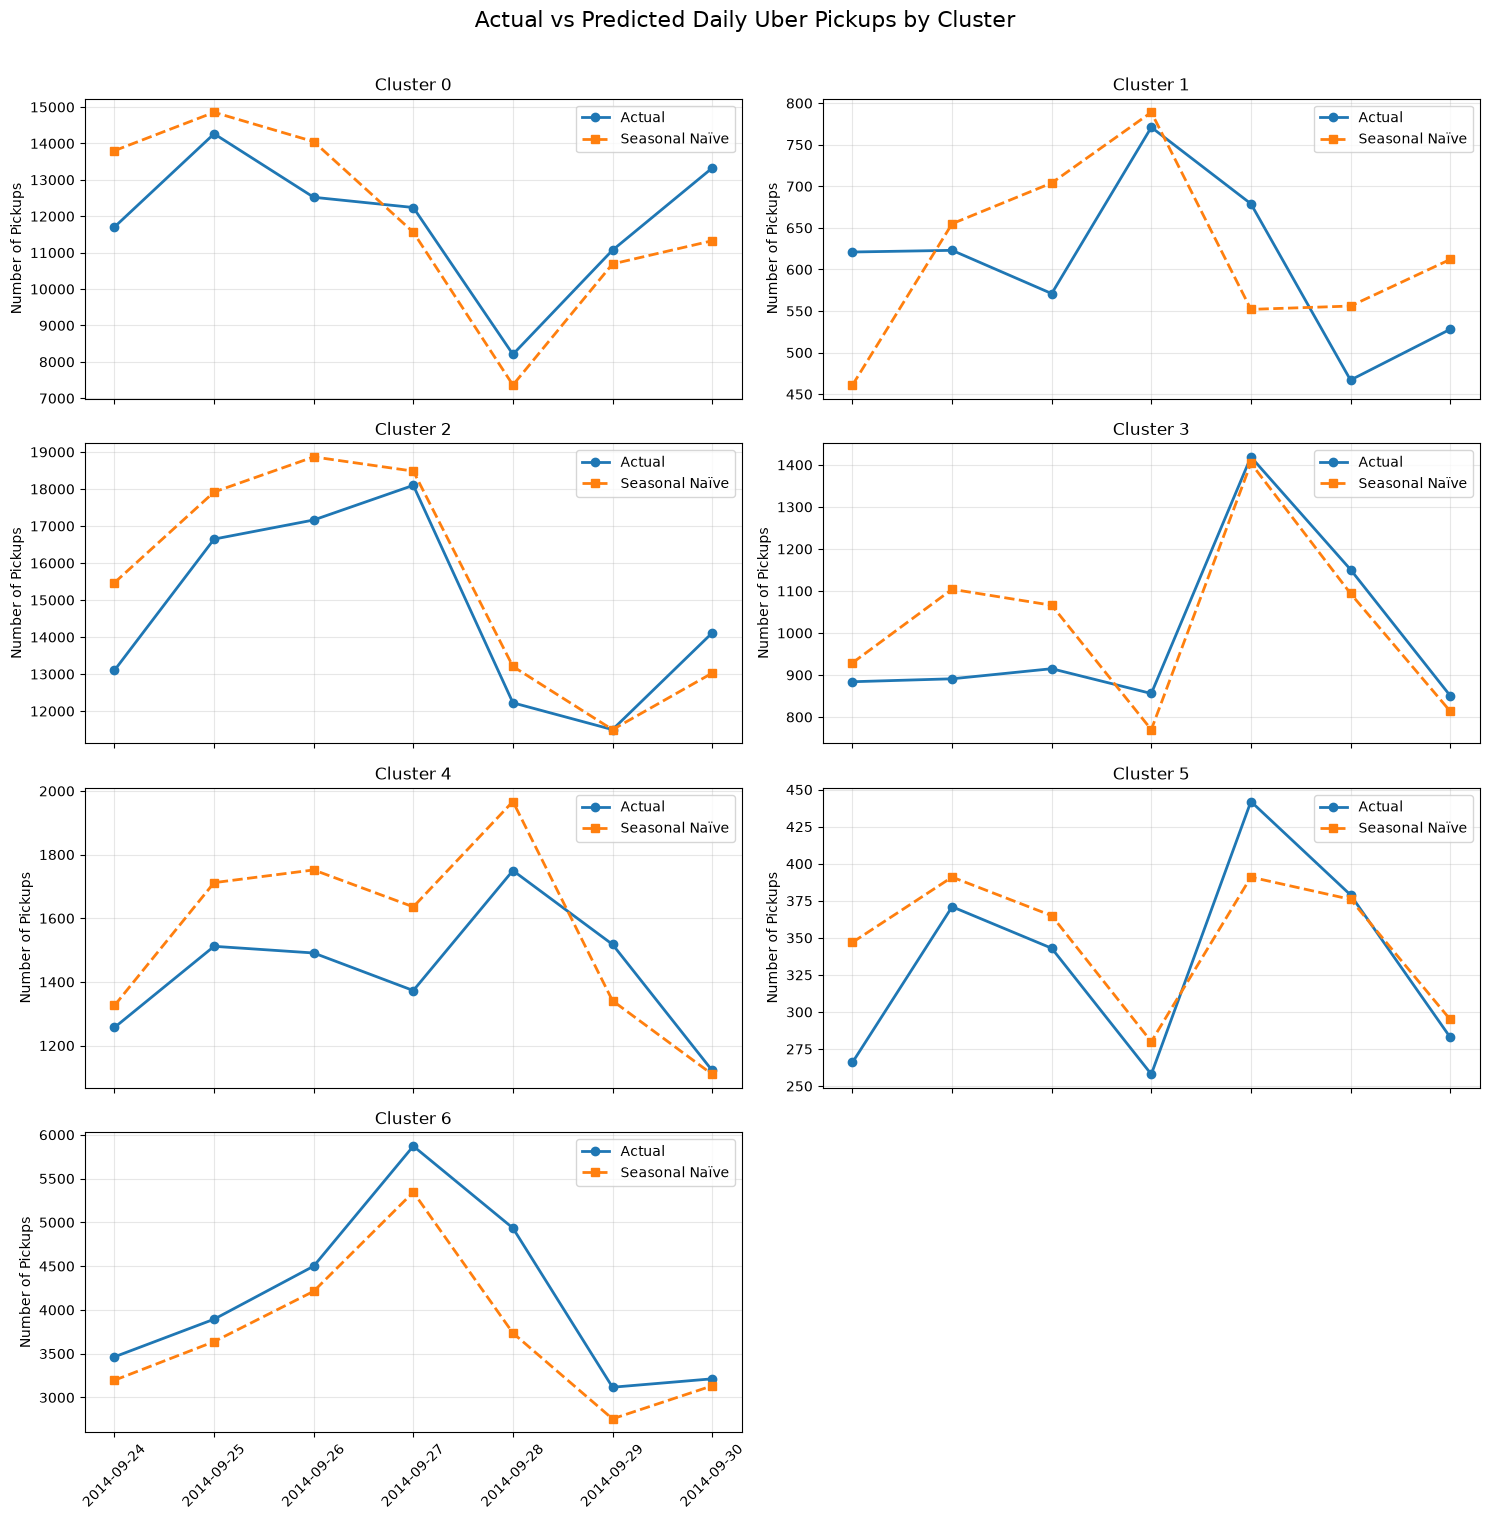

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    4, 2,
    figsize=(15, 15),
    sharex=True
)

axes = axes.flatten()

for i, cluster in enumerate(test.columns):

    ax = axes[i]

    ax.plot(
        test.index,
        test[cluster],
        marker="o",
        linewidth=2,
        label="Actual"
    )

    ax.plot(
        seasonal_predictions.index,
        seasonal_predictions[cluster],
        marker="s",
        linestyle="--",
        linewidth=2,
        label="Seasonal Naïve"
    )

    ax.set_title(f"Cluster {cluster}")
    ax.set_ylabel("Number of Pickups")
    ax.grid(alpha=0.3)
    ax.legend()

    ax.tick_params(
        axis="x",
        rotation=45
    )

# Remove the unused eighth subplot
fig.delaxes(axes[-1])

fig.suptitle(
    "Actual vs Predicted Daily Uber Pickups by Cluster",
    fontsize=16,
    y=1.01
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "04_seasonal_naive_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Historical average for each day of the week
training_weekdays = train.index.dayofweek

weekday_averages = train.groupby(training_weekdays).mean()

# Predict the test period using training averages
weekday_predictions = pd.DataFrame(
    index=test.index,
    columns=test.columns,
    dtype=float
)

for date in test.index:
    weekday = date.dayofweek
    weekday_predictions.loc[date] = weekday_averages.loc[weekday].values

# Evaluate both forecasting models
results = []

for model_name, predictions in [
    ("Seasonal Naive", seasonal_predictions),
    ("Day-of-Week Average", weekday_predictions)
]:
    actual = test.to_numpy().ravel()
    predicted = predictions.to_numpy().ravel()

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)

    results.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "MSE": round(mse, 2),
        "RMSE": round(rmse, 2)
    })

comparison = pd.DataFrame(results)

print("FORECASTING MODEL COMPARISON")
display(comparison)
comparison.to_csv(
    RESULTS_DIR / "04_model_comparison.csv",
    index=False
)


FORECASTING MODEL COMPARISON


/var/folders/y8/1y7nwpsd41z4f87mjnvk4_tr0000gn/T/ipykernel_8144/546832127.py:6: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  training_weekdays = train.index.dayofweek
/var/folders/y8/1y7nwpsd41z4f87mjnvk4_tr0000gn/T/ipykernel_8144/546832127.py:18: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  weekday = date.dayofweek


,Model,MAE,MSE,RMSE
0,Seasonal Naive,439.59,556953.55,746.29
1,Day-of-Week Average,353.90,415409.26,644.52


In [19]:
# Compare forecasting performance within each cluster

cluster_results = []

for cluster in test.columns:
    actual = test[cluster]

    for model_name, predictions in [
        ("Seasonal Naive", seasonal_predictions),
        ("Day-of-Week Average", weekday_predictions)
    ]:
        predicted = predictions[cluster]

        cluster_results.append({
            "Cluster": cluster,
            "Model": model_name,
            "MAE": round(mean_absolute_error(actual, predicted), 2),
            "RMSE": round(np.sqrt(
                mean_squared_error(actual, predicted)
            ), 2)
        })

cluster_comparison = pd.DataFrame(cluster_results)

print("FORECASTING PERFORMANCE BY CLUSTER")
display(cluster_comparison)
cluster_comparison.to_csv(
    RESULTS_DIR / "04_cluster_model_comparison.csv",
    index=False
)

# Identify the best model for each cluster
best_models = (
    cluster_comparison
    .sort_values(["Cluster", "MAE"])
    .drop_duplicates(subset="Cluster")
    .reset_index(drop=True)
)

print("\nBEST FORECASTING MODEL FOR EACH CLUSTER")
display(best_models)
best_models.to_csv(
    RESULTS_DIR / "04_best_models_by_cluster.csv",
    index=False
)

FORECASTING PERFORMANCE BY CLUSTER


,Cluster,Model,MAE,RMSE
0,0,Seasonal Naive,1159.00,1330.01
1,0,Day-of-Week Average,826.74,1069.13
2,1,Seasonal Naive,91.86,104.02
3,1,Day-of-Week Average,53.44,65.46
4,2,Seasonal Naive,1113.43,1331.41
5,2,Day-of-Week Average,1067.73,1255.30
6,3,Seasonal Naive,86.29,108.52
7,3,Day-of-Week Average,81.88,93.14
8,4,Seasonal Naive,171.29,192.95
9,4,Day-of-Week Average,63.92,78.73



BEST FORECASTING MODEL FOR EACH CLUSTER


,Cluster,Model,MAE,RMSE
0,0,Day-of-Week Average,826.74,1069.13
1,1,Day-of-Week Average,53.44,65.46
2,2,Day-of-Week Average,1067.73,1255.30
3,3,Day-of-Week Average,81.88,93.14
4,4,Day-of-Week Average,63.92,78.73
5,5,Seasonal Naive,30.14,39.07
6,6,Day-of-Week Average,350.74,409.81


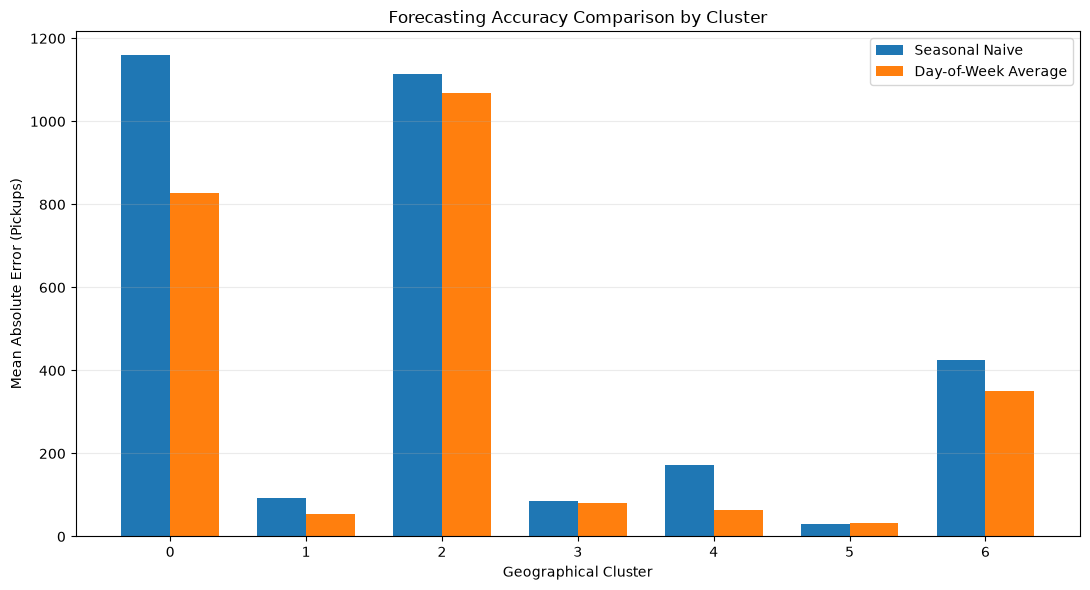

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Compare MAE for both forecasting models
mae_comparison = cluster_comparison.pivot(
    index="Cluster",
    columns="Model",
    values="MAE"
)

clusters = mae_comparison.index.to_numpy()
x = np.arange(len(clusters))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    mae_comparison["Seasonal Naive"],
    width,
    label="Seasonal Naive"
)

ax.bar(
    x + width / 2,
    mae_comparison["Day-of-Week Average"],
    width,
    label="Day-of-Week Average"
)

ax.set_xlabel("Geographical Cluster")
ax.set_ylabel("Mean Absolute Error (Pickups)")
ax.set_title("Forecasting Accuracy Comparison by Cluster")

ax.set_xticks(x)
ax.set_xticklabels(clusters)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "04_forecasting_mae_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()